In [13]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/titanic_cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S


In [2]:
# Select the input features for prediction
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]

X = df[features]
y = df["Survived"]

print("Input features:")
print(X.head())

print("\nTarget variable:")
print(y.head())

print("\nNumber of input features:", X.shape[1])
print("Number of target values:", len(y))

Input features:
   Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0       3    male  22.0      1      0   7.2500        S
1       1  female  38.0      1      0  71.2833        C
2       3  female  26.0      0      0   7.9250        S
3       1  female  35.0      1      0  53.1000        S
4       3    male  35.0      0      0   8.0500        S

Target variable:
0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

Number of input features: 7
Number of target values: 891


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 712
Testing samples: 179


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Sex", "Embarked"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [3]:
from sklearn.pipeline import Pipeline


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Sex", "Embarked"]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")
print(preprocessor)

Preprocessing pipeline created successfully!
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Sex', 'Embarked'])])


In [14]:
from sklearn.model_selection import train_test_split

features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]

X = df[features]
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 712
Testing samples: 179


In [15]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model training completed successfully!")
print("Baseline accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

Model training completed successfully!
Baseline accuracy: 80.45 %


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))
print("F1-score:", round(f1_score(y_test, y_pred), 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.804
Precision: 0.793
Recall: 0.667
F1-score: 0.724

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



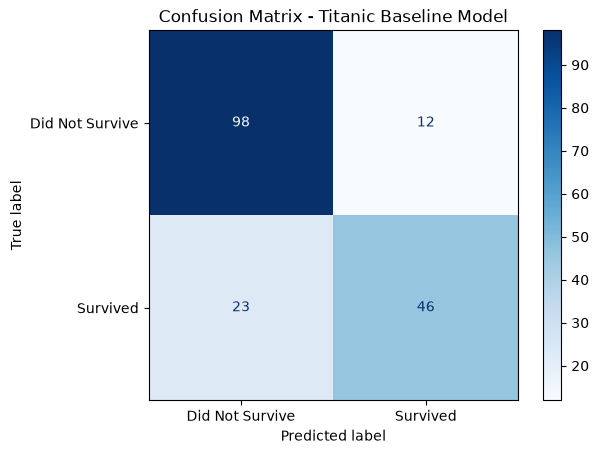

Confusion matrix:
[[98 12]
 [23 46]]


In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did Not Survive", "Survived"]
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix - Titanic Baseline Model")
plt.show()

print("Confusion matrix:")
print(cm)

## Model Limitations

The baseline Logistic Regression model provides an initial estimate of how well passenger survival can be predicted from the selected Titanic dataset features. However, several limitations should be considered.

### 1. Limited Dataset

The model uses only 891 passenger records from the Titanic dataset. The patterns learned may not generalize to other populations or situations.

### 2. Limited Feature Selection

The model uses passenger class, sex, age, number of siblings or spouses, number of parents or children, fare, and embarkation port. Other information, such as cabin details or ticket characteristics, was not included in this baseline.

### 3. Missing-Value Imputation

Missing ages were replaced with the median, while missing cabin and embarkation information was handled during data cleaning. These replacements may not represent the passengers' actual information and can influence the results.

### 4. Model Assumptions

Logistic Regression models relationships between features and the probability of survival using a linear decision boundary in the transformed feature space. It may not capture complex interactions or nonlinear patterns.

### 5. Evaluation Depends on the Data Split

The evaluation uses one train-test split. Performance may change with a different split, so cross-validation would provide a more robust estimate.

### 6. Accuracy Is Not Sufficient Alone

Accuracy does not explain every type of prediction error. Precision, recall, F1-score, and the confusion matrix are also necessary to understand how the model predicts survivors and non-survivors.

### Conclusion

A Logistic Regression model was developed as a baseline for predicting Titanic passenger survival. Its performance was evaluated using classification metrics and a confusion matrix. The results provide a starting point for future work, including cross-validation, feature engineering, and comparison with other classification algorithms.